## **Isolation Forest Anomaly Detection**

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n_samples_per_cluster = 500

# Cluster 1: Center at (30, 30)
x1 = np.random.normal(30, 4, n_samples_per_cluster)
y1 = np.random.normal(30, 4, n_samples_per_cluster)

# Cluster 2: Center at (70, 70)
x2 = np.random.normal(70, 4, n_samples_per_cluster)
y2 = np.random.normal(70, 4, n_samples_per_cluster)

# Combine clusters
x_normal = np.concatenate([x1, x2])
y_normal = np.concatenate([y1, y2])

# Generate outliers across the entire 0-100 space
n_outliers = 150
x_outliers = np.random.uniform(0, 100, n_outliers)
y_outliers = np.random.uniform(0, 100, n_outliers)

# Final combination
x = np.concatenate([x_normal, x_outliers])
y = np.concatenate([y_normal, y_outliers])

df = pd.DataFrame({'Feature_1': x, 'Feature_2': y})
display(df.head())
print(f'Total rows: {len(df)}')

,Feature_1,Feature_2
0,31.986857,33.704710
1,29.446943,37.637667
2,32.590754,24.405730
3,36.092119,32.251877
4,29.063387,27.397430


Total rows: 1150


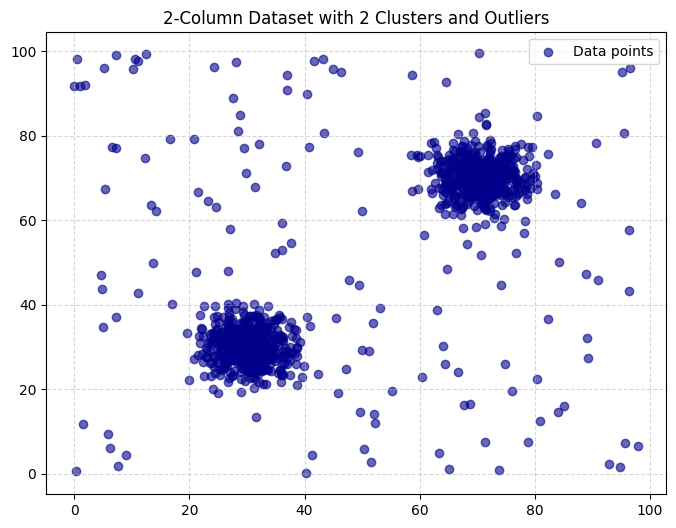

In [67]:
# Plot the 2 clusters with outliers
plt.figure(figsize=(8, 6))
plt.scatter(df['Feature_1'], df['Feature_2'], color='darkblue', alpha=0.6, label='Data points')
plt.title('2-Column Dataset with 2 Clusters and Outliers')
#plt.xlabel('Feature 1')
#plt.ylabel('Feature 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [68]:
from sklearn.ensemble import IsolationForest

In [69]:
clf=IsolationForest(contamination='auto')
clf.fit(df)
predictions=clf.predict(df)

In [70]:
## waha -1 outliers hai or 1 actual values
predictions

array([ 1,  1,  1, ..., -1,  1,  1])

In [71]:
import numpy as np
index=np.where(predictions < 0)
index


(array([  44,  146,  168,  179,  209,  221,  262,  478,  539,  561,  597,
         601,  615,  660,  846,  926,  957,  971, 1000, 1001, 1002, 1003,
        1004, 1005, 1006, 1007, 1008, 1010, 1011, 1013, 1014, 1015, 1016,
        1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028,
        1029, 1031, 1032, 1033, 1034, 1035, 1036, 1037, 1038, 1039, 1040,
        1041, 1042, 1043, 1044, 1045, 1046, 1048, 1049, 1050, 1051, 1052,
        1053, 1054, 1056, 1057, 1058, 1059, 1061, 1062, 1063, 1064, 1065,
        1066, 1067, 1068, 1070, 1071, 1072, 1073, 1074, 1075, 1076, 1077,
        1078, 1079, 1080, 1081, 1082, 1083, 1084, 1085, 1086, 1087, 1088,
        1089, 1090, 1091, 1092, 1093, 1094, 1095, 1096, 1097, 1098, 1099,
        1100, 1101, 1102, 1103, 1104, 1105, 1106, 1107, 1108, 1109, 1110,
        1112, 1113, 1114, 1115, 1116, 1117, 1118, 1119, 1120, 1122, 1123,
        1125, 1126, 1127, 1128, 1129, 1130, 1131, 1132, 1133, 1134, 1137,
        1138, 1139, 1140, 1141, 1142, 

In [72]:
x=df.values

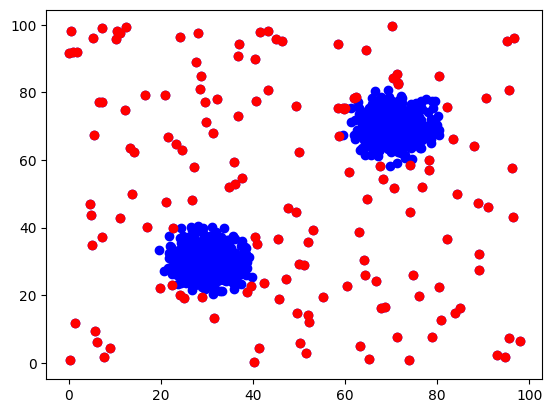

In [73]:
index=np.where(predictions < 0)
plt.scatter(x[:,0],x[:,1],color='b')
plt.scatter(x[index,0],x[index,1],color='r')
plt.show()

##**DBSCAN Clustering**

Main aim to find outliers in non-linear dataset in DBSCAN

In [20]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import make_circles

In [9]:
X,y=make_circles(n_samples=750, factor=0.3,noise=0.1)

In [19]:
X

array([[ 0.17921255, -0.01470709],
       [-0.07707092, -0.21406663],
       [ 0.41920144,  0.87817621],
       ...,
       [ 1.0087048 ,  0.09229919],
       [-0.09771497, -0.26143632],
       [-0.35529727, -0.02296043]])

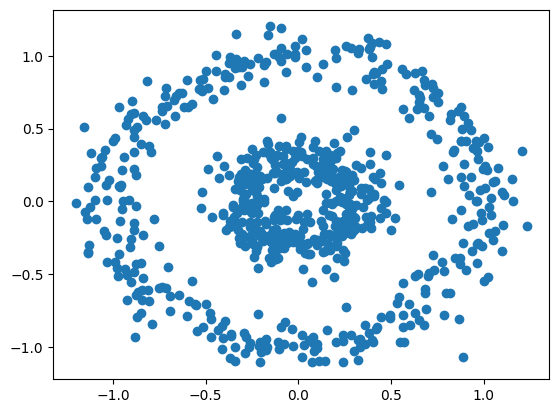

In [11]:
plt.scatter(X[:,0],X[:,1])

In [14]:
from sklearn.cluster import DBSCAN

In [15]:
dbcan=DBSCAN(eps=0.1)


In [16]:
# Waha -1 outliers hai and 1 actual values hai
dbcan.fit_predict(X)

array([ 0,  0,  1,  2,  3,  0, -1,  0, -1,  2,  0,  3,  0, -1,  4, -1,  0,
        2,  0,  0,  0,  0,  0,  5,  0,  3,  0,  0,  0,  2,  0,  0,  0,  6,
        0,  0,  0,  0,  0, -1,  2,  0,  0,  7,  0,  0,  0,  0,  2,  7,  0,
        8, -1,  5,  0,  4,  5, -1,  3,  5,  7,  7,  5,  0,  0,  0,  7,  6,
        0,  0,  7,  8,  7,  0,  8,  0,  7,  7,  9,  5,  0,  0,  0, -1,  0,
        4,  0,  2,  0,  0,  4,  0,  0,  2,  0,  7,  5,  0,  0,  2, -1,  8,
        0,  0,  3,  0, -1,  0,  2,  0,  4,  7,  0,  0,  0,  0,  1,  0,  2,
        0,  0,  4, -1,  7,  0,  0, -1,  0, -1,  0,  6,  3,  0,  0,  6,  7,
        6,  5,  0,  7,  4,  0,  0,  0,  0, -1,  7,  0,  0,  7,  2,  0,  0,
        0,  7,  0,  7,  0,  0,  0,  3,  5,  0,  0,  7,  2,  7,  0,  2,  0,
        0,  0,  6,  0,  0,  6,  1,  2,  0,  7,  0,  0,  6,  3,  6,  0,  0,
        0,  3,  0,  0,  0,  1, -1,  6,  0, -1,  5,  0,  6,  0,  7,  0,  0,
        0,  0,  2,  5, 10,  0,  0,  2,  7,  1,  0,  0,  0,  4,  9,  7,  0,
        8,  3,  7,  0,  7

In [17]:
### output
dbcan.labels_

array([ 0,  0,  1,  2,  3,  0, -1,  0, -1,  2,  0,  3,  0, -1,  4, -1,  0,
        2,  0,  0,  0,  0,  0,  5,  0,  3,  0,  0,  0,  2,  0,  0,  0,  6,
        0,  0,  0,  0,  0, -1,  2,  0,  0,  7,  0,  0,  0,  0,  2,  7,  0,
        8, -1,  5,  0,  4,  5, -1,  3,  5,  7,  7,  5,  0,  0,  0,  7,  6,
        0,  0,  7,  8,  7,  0,  8,  0,  7,  7,  9,  5,  0,  0,  0, -1,  0,
        4,  0,  2,  0,  0,  4,  0,  0,  2,  0,  7,  5,  0,  0,  2, -1,  8,
        0,  0,  3,  0, -1,  0,  2,  0,  4,  7,  0,  0,  0,  0,  1,  0,  2,
        0,  0,  4, -1,  7,  0,  0, -1,  0, -1,  0,  6,  3,  0,  0,  6,  7,
        6,  5,  0,  7,  4,  0,  0,  0,  0, -1,  7,  0,  0,  7,  2,  0,  0,
        0,  7,  0,  7,  0,  0,  0,  3,  5,  0,  0,  7,  2,  7,  0,  2,  0,
        0,  0,  6,  0,  0,  6,  1,  2,  0,  7,  0,  0,  6,  3,  6,  0,  0,
        0,  3,  0,  0,  0,  1, -1,  6,  0, -1,  5,  0,  6,  0,  7,  0,  0,
        0,  0,  2,  5, 10,  0,  0,  2,  7,  1,  0,  0,  0,  4,  9,  7,  0,
        8,  3,  7,  0,  7

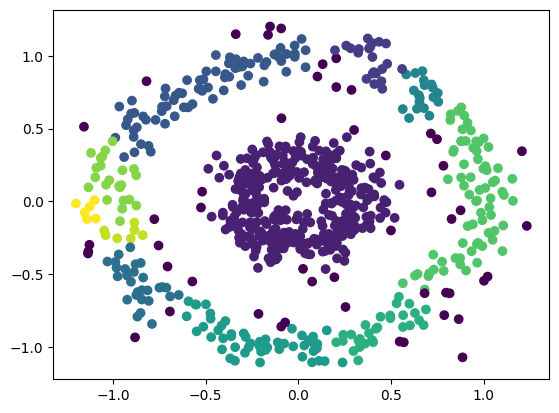

In [18]:
plt.scatter(X[:,0],X[:,1],c=dbcan.labels_) # c=dbcan.labels_

##**Local Factor outliers**

In [33]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.datasets import make_circles

In [34]:
X,y=make_circles(n_samples=750, factor=0.3,noise=0.1)

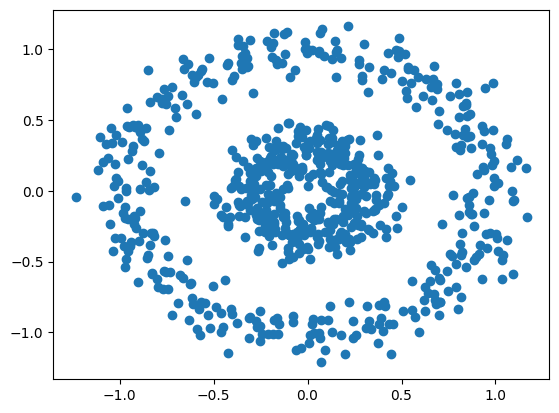

In [35]:
plt.scatter(X[:,0],X[:,1])

In [36]:
from sklearn.neighbors import LocalOutlierFactor

In [37]:
local_outliers=LocalOutlierFactor(n_neighbors= 20,algorithm= "auto",metric= "minkowski")

In [38]:
# Waha -1 outliers hai and 1 actual values hai
local_outliers.fit_predict(X)

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1

In [40]:
### output
# Store the output of fit_predict directly
predictions = local_outliers.fit_predict(X)
predictions

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1

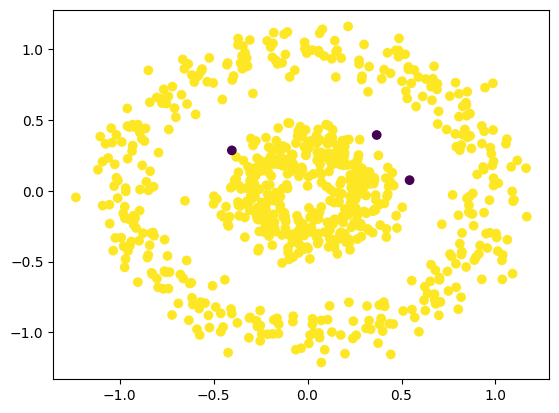

In [41]:
plt.scatter(X[:,0], X[:,1], c=predictions)